In [2]:
from bs4 import BeautifulSoup
import urllib.request
import pandas as pd
import datetime
import requests
from selenium import webdriver
from selenium.webdriver.common.by import By
import time
import random
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import math
from scipy import stats
from statsmodels.formula.api import ols, glm
#버전 차이로 인한 warning문구 생략
import warnings
warnings.filterwarnings(action='ignore')

In [3]:
import statsmodels.api as sm

In [ ]:
flights = sns.load_dataset("flights")
flights

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121
...,...,...,...
139,1960,Aug,606
140,1960,Sep,508
141,1960,Oct,461
142,1960,Nov,390


In [ ]:
#1번
print(flights.groupby('year',observed=False)['passengers'].agg(['sum','mean']))
result = flights.groupby('month',observed=False)['passengers'].agg(['sum','mean'])
print(result.sort_values('mean',ascending=False))
#과학기술이 발전함에 따라 세계회가 진행되며 비행기를 타는 승객수가 점진적으로 증가하고 있다
#역시 여름에 다들 해외로 놀러간다. 7월 goat

       sum        mean
year                  
1949  1520  126.666667
1950  1676  139.666667
1951  2042  170.166667
1952  2364  197.000000
1953  2700  225.000000
1954  2867  238.916667
1955  3408  284.000000
1956  3939  328.250000
1957  4421  368.416667
1958  4572  381.000000
1959  5140  428.333333
1960  5714  476.166667
        sum        mean
month                  
Jul    4216  351.333333
Aug    4213  351.083333
Jun    3740  311.666667
Sep    3629  302.416667
May    3262  271.833333
Mar    3242  270.166667
Apr    3205  267.083333
Oct    3199  266.583333
Dec    3142  261.833333
Jan    2901  241.750000
Feb    2820  235.000000
Nov    2794  232.833333


In [ ]:
#2번
flights['flights_rank'] = flights['passengers'].rank(pct=True)
bins = [0, 0.2, 0.5, 1.0]
labels = ["low-traffic","mid-traffic",'high-traffic']
flights['traffic_level'] = pd.cut(flights['flights_rank'],bins=bins,labels=labels)
flights.groupby(['month','traffic_level'],observed=False)['passengers'].mean().sort_values(ascending=False).head(3)
#7,8,6 순서가 1등 2등 3등이므로 여름철 휴가기간에 비행기를 제일 많이 탑승한다.

month  traffic_level
Jul    high-traffic     457.857143
Aug    high-traffic     431.750000
Jun    high-traffic     425.500000
Name: passengers, dtype: float64

In [ ]:
flights['month']

In [ ]:
#3번
def season(month):
    if month in 'Jan, Feb, Dec':
        return 'winter'
    elif month in 'Mar, Apr, May':
        return 'spring'
    elif month in 'Jun, Jul, Aug':
        return 'summer'
    else:
        return 'fall'

In [ ]:
def period(year):
    if year <= 1952:
        return 'early'
    else:
        return 'late'

In [ ]:
print(flights.groupby('season')['passengers'].sum())
flights['season']=flights['month'].apply(season)
flights['period']=flights['year'].apply(period)
result = flights.groupby(['season','period'])['passengers'].agg(['mean','var','std','count'])
result['Stable Peak Season'] = result['mean'] / (result['std']/result['mean'] + 0.1)
result.sort_values('Stable Peak Season',ascending=False)
#표준편차를 mean으로 나누어 데이터 스케일에 대한 차이를 줄여줌(분모 크기 낮추기)
#기간은 비교적 최근일수록 비행기를 많이 타며 여름 봄 순으로 비행기를 많이 타며 가을과 겨울은 대체로 비슷하다.

season
fall       9622
spring     9709
summer    12169
winter     8863
Name: passengers, dtype: int64


,,mean,var,std,count,Stable Peak Season
season,period,,,,,
summer,late,415.958333,12922.128623,113.675541,24,1114.315731
spring,late,327.333333,5920.579710,76.945303,24,976.918699
fall,late,324.750000,7956.717391,89.200434,24,866.753125
winter,late,297.000000,5555.391304,74.534497,24,846.255340
summer,early,182.166667,1244.696970,35.280263,12,620.310260
spring,early,154.416667,694.446970,26.352362,12,570.524255
winter,early,144.583333,781.719697,27.959251,12,492.822512
fall,early,152.333333,1074.424242,32.778411,12,483.328499


In [ ]:
import pandas as pd
print(pd.__version__)

2.3.3


In [4]:
penguins = sns.load_dataset('penguins')

In [42]:
type(penguins)

pandas.core.frame.DataFrame

In [ ]:
penguins.info

<bound method DataFrame.info of     species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0    Adelie  Torgersen            39.1           18.7              181.0   
1    Adelie  Torgersen            39.5           17.4              186.0   
2    Adelie  Torgersen            40.3           18.0              195.0   
3    Adelie  Torgersen             NaN            NaN                NaN   
4    Adelie  Torgersen            36.7           19.3              193.0   
..      ...        ...             ...            ...                ...   
339  Gentoo     Biscoe             NaN            NaN                NaN   
340  Gentoo     Biscoe            46.8           14.3              215.0   
341  Gentoo     Biscoe            50.4           15.7              222.0   
342  Gentoo     Biscoe            45.2           14.8              212.0   
343  Gentoo     Biscoe            49.9           16.1              213.0   

     body_mass_g     sex  
0         3750.0    Male  
1

In [ ]:
penguins.groupby(['species','sex'])['body_mass_g'].mean()

species    sex   
Adelie     Female    3368.835616
           Male      4043.493151
Chinstrap  Female    3527.205882
           Male      3938.970588
Gentoo     Female    4679.741379
           Male      5484.836066
Name: body_mass_g, dtype: float64

In [9]:
male_penguins = penguins.loc[penguins['sex'] == 'Male', 'body_mass_g']
female_penguins = penguins.loc[penguins['sex'] == 'Female', 'body_mass_g']
print(stats.ttest_ind(male_penguins, female_penguins, equal_var = False))
Rformula = 'body_mass_g ~ bill_length_mm + flipper_length_mm + species * sex'
regression_result = ols(Rformula, data = penguins).fit()
regression_result.summary()

TtestResult(statistic=np.float64(8.554537231165762), pvalue=np.float64(4.793891255051459e-16), df=np.float64(323.8958810286485))


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            body_mass_g   R-squared:                       0.879
Model:                            OLS   Adj. R-squared:                  0.877
Method:                 Least Squares   F-statistic:                     338.8
Date:                Fri, 12 Jun 2026   Prob (F-statistic):          3.62e-145
Time:                        09:52:36   Log-Likelihood:                -2347.9
No. Observations:                 333   AIC:                             4712.
Df Residuals:                     325   BIC:                             4742.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
====================================================================================================
                                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
Intercept                         -940.9089    536.622     -1.753      0.080   -1996.601     114.783
species[T.Chinstrap]              -138.3578     86.079     -1.607      0.109    -307.701      30.985
species[T.Gentoo]                  657.8754     94.272      6.978      0.000     472.415     843.336
sex[T.Male]                        515.1238     51.943      9.917      0.000     412.936     617.311
species[T.Chinstrap]:sex[T.Male]  -361.0644     83.861     -4.306      0.000    -526.043    -196.086
species[T.Gentoo]:sex[T.Male]       35.0874     70.815      0.495      0.621    -104.227     174.402
bill_length_mm                      24.1723      6.943      3.481      0.001      10.513      37.832
flipper_length_mm                   18.1536      2.843      6.385      0.000      12.561      23.747
==============================================================================
Omnibus:                        0.428   Durbin-Watson:                   2.066
Prob(Omnibus):                  0.807   Jarque-Bera (JB):                0.415
Skew:                           0.085   Prob(JB):                        0.813
Kurtosis:                       2.973   Cond. No.                     7.23e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 7.23e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

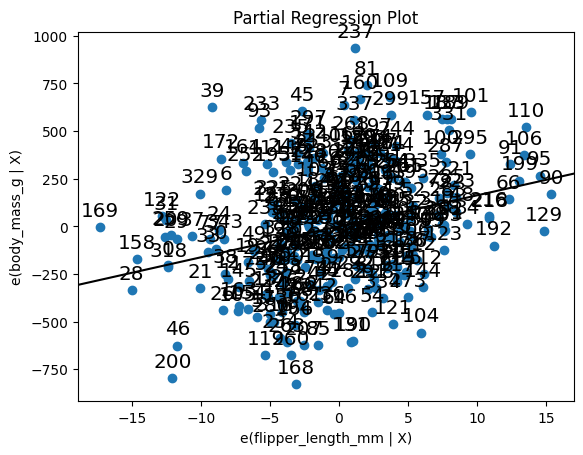

In [10]:
analysis_cols = ["body_mass_g", "flipper_length_mm", "bill_length_mm", "species", "sex"]
penguins_clean = penguins.dropna(subset=analysis_cols)
others = list(set(penguins.columns).difference(set(["body_mass_g", "flipper_length_mm"])))
p, resids = sm.graphics.plot_partregress("body_mass_g", "flipper_length_mm", others, data = penguins_clean, ret_coords = True)

In [93]:
penguins.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [11]:
stats.ttest_ind(male_penguins, female_penguins, equal_var = False)

TtestResult(statistic=np.float64(8.554537231165762), pvalue=np.float64(4.793891255051459e-16), df=np.float64(323.8958810286485))

In [74]:
Rformula = 'body_mass_g ~ bill_length_mm + flipper_length_mm + species * sex'

In [75]:
regression_result = ols(Rformula, data = penguins).fit()

In [76]:
regression_result.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            body_mass_g   R-squared:                       0.879
Model:                            OLS   Adj. R-squared:                  0.877
Method:                 Least Squares   F-statistic:                     338.8
Date:                Thu, 11 Jun 2026   Prob (F-statistic):          3.62e-145
Time:                        16:48:06   Log-Likelihood:                -2347.9
No. Observations:                 333   AIC:                             4712.
Df Residuals:                     325   BIC:                             4742.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
====================================================================================================
                                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
Intercept                         -940.9089    536.622     -1.753      0.080   -1996.601     114.783
species[T.Chinstrap]              -138.3578     86.079     -1.607      0.109    -307.701      30.985
species[T.Gentoo]                  657.8754     94.272      6.978      0.000     472.415     843.336
sex[T.Male]                        515.1238     51.943      9.917      0.000     412.936     617.311
species[T.Chinstrap]:sex[T.Male]  -361.0644     83.861     -4.306      0.000    -526.043    -196.086
species[T.Gentoo]:sex[T.Male]       35.0874     70.815      0.495      0.621    -104.227     174.402
bill_length_mm                      24.1723      6.943      3.481      0.001      10.513      37.832
flipper_length_mm                   18.1536      2.843      6.385      0.000      12.561      23.747
==============================================================================
Omnibus:                        0.428   Durbin-Watson:                   2.066
Prob(Omnibus):                  0.807   Jarque-Bera (JB):                0.415
Skew:                           0.085   Prob(JB):                        0.813
Kurtosis:                       2.973   Cond. No.                     7.23e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 7.23e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [77]:
others = list(set(penguins.columns).difference(set(["body_mass_g", "flipper_length_mm"])))

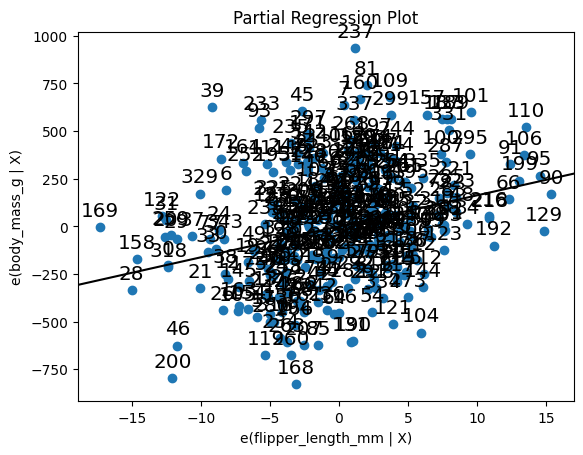

In [84]:
#plot_partregress의 그래프는 경향에 맞게 선을 그어준다.
p, resids = sm.graphics.plot_partregress("body_mass_g", "flipper_length_mm", others, data = penguins_clean, ret_coords = True)

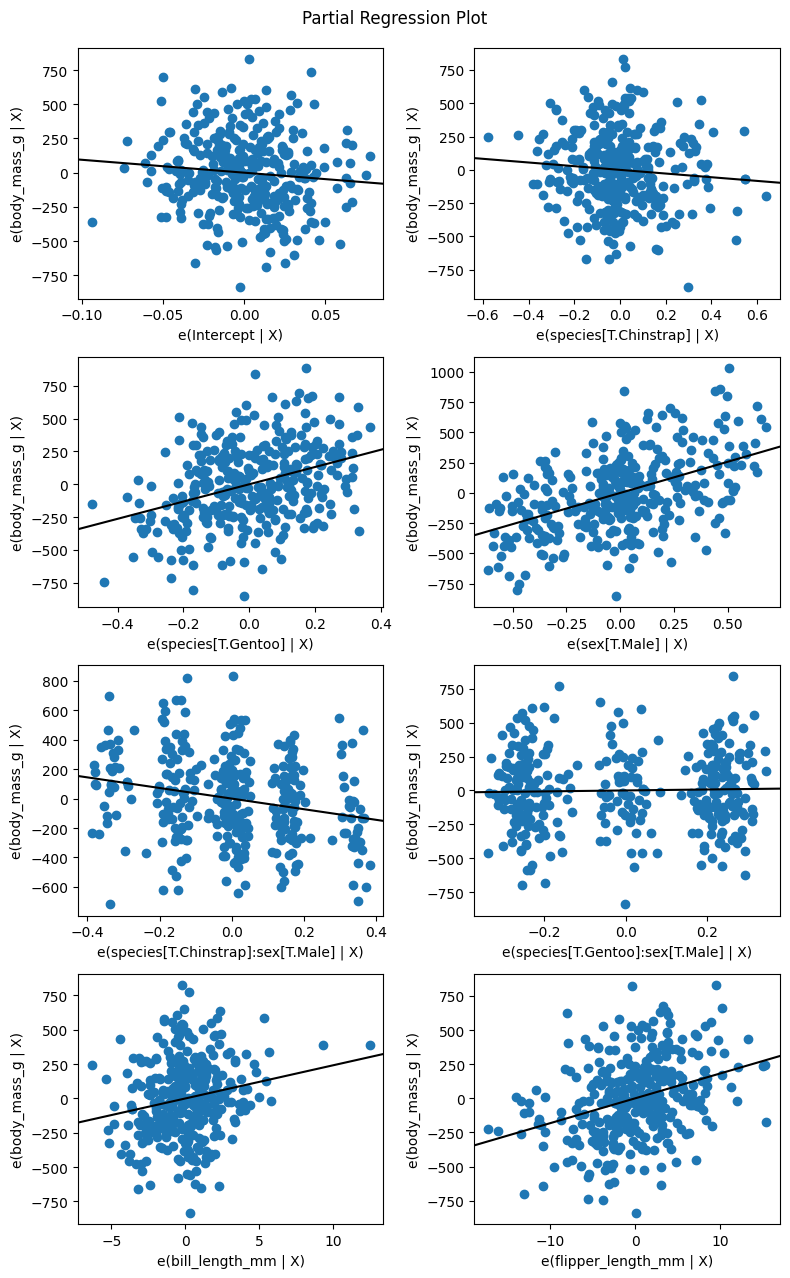

In [91]:
fig = plt.figure(figsize = (8, 13))
sm.graphics.plot_partregress_grid(regression_result, fig = fig)
plt.show()